# NEU feature engineering (CPU)
**HOG · Local Binary Patterns · intensity statistics · PCA exploration**

This notebook uses **training images only**. The existing `validation` directory is reserved for the final evaluation. No classifier is trained here.

**Methodology:** Convert each RGB-encoded grayscale image to 64×64 grayscale, extract complementary descriptors, and inspect a *training-only* PCA. During Step 4, scaler and PCA will be fitted **inside each cross-validation training fold** to avoid leakage. Never fit preprocessing on the full training set before CV.

## 1. Locate the dataset and validate the training manifest

In [1]:
from pathlib import Path
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import joblib

root_hint = os.environ.get('NEU_PROJECT_ROOT')
candidates = ([Path(root_hint).expanduser()] if root_hint else []) + [Path.home()/'base'/'NEU_Steel_Defects_CPU', Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p/'outputs'/'step1_dataset_manifest.csv').is_file()), None)
if ROOT is None: raise FileNotFoundError('Cannot locate step1_dataset_manifest.csv; set NEU_PROJECT_ROOT.')
OUT = ROOT/'outputs'; OUT.mkdir(exist_ok=True)
manifest = pd.read_csv(OUT/'step1_dataset_manifest.csv')
required = {'path','split','label','sha256'}
assert required.issubset(manifest.columns), f'Missing columns: {required-set(manifest.columns)}'
train = manifest.loc[manifest['split'].eq('train')].copy().sort_values('path').reset_index(drop=True)
heldout = manifest.loc[manifest['split'].eq('validation')]
assert len(train)==1440 and len(heldout)==360, 'Unexpected split sizes: inspect manifest.'
assert not set(train.sha256).intersection(set(heldout.sha256)), 'Exact cross-split duplicate: stop and investigate.'
print('Project:', ROOT, '| training:',len(train),'| reserved test:',len(heldout))

Project: /home/eren/base/NEU_Steel_Defects_CPU | training: 1440 | reserved test: 360


## 2. Remove exact duplicates from training only
Keep the first path for each SHA-256. Do not change original image files. The 360-image test directory remains untouched.

In [2]:
duplicates = train.loc[train.duplicated('sha256', keep=False), ['path','label','sha256']]
display(duplicates)
if not duplicates.empty:
    assert (train.groupby('sha256')['label'].nunique() == 1).all(), 'Conflicting labels for identical files.'
train_unique = train.drop_duplicates('sha256',keep='first').reset_index(drop=True)
print('Training images after deduplication:',len(train_unique))
print('Class counts:',train_unique.label.value_counts().sort_index().to_dict())

,path,label,sha256
483,data/raw/NEU-DET/train/images/patches/patches_...,patches,4d2de82731b86cdbc7a66f2a9bfb01074bb4cb65e47bcc...
487,data/raw/NEU-DET/train/images/patches/patches_...,patches,4d2de82731b86cdbc7a66f2a9bfb01074bb4cb65e47bcc...


Training images after deduplication: 1439
Class counts: {'crazing': 240, 'inclusion': 240, 'patches': 239, 'pitted_surface': 240, 'rolled-in_scale': 240, 'scratches': 240}


## 3. Feature definitions
- **HOG**: edge orientation and spatial structure (9 orientations, 8×8-pixel cells, 2×2-cell blocks).
- **LBP**: local texture histogram (uniform LBP, radius 1, 8 neighbors, 10 bins).
- **Intensity statistics**: 12 measures (mean, std, min, max, 10th/25th/50th/75th/90th percentiles, mean gradient magnitude, gradient std, entropy).

Features are extracted independently for each image; no dataset-wide scaling or PCA occurs here. The feature vector will have more than the teacher's required 10 attributes.

In [3]:
from scipy.stats import entropy
SIZE=(64,64)
LBP_P=8; LBP_R=1

def extract_features(path):
    with Image.open(path) as im:
        gray=np.asarray(im.convert('L').resize(SIZE, Image.Resampling.BILINEAR), dtype=np.float32)
    scaled=gray/255.0
    h=hog(scaled, orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm='L2-Hys', feature_vector=True)
    # LBP works on uint8 intensities; do not run on floating-point images.
    lbp=local_binary_pattern(gray.astype(np.uint8), P=LBP_P, R=LBP_R, method='uniform')
    hist=np.histogram(lbp, bins=np.arange(LBP_P+3), density=False)[0].astype(np.float32)
    hist/=max(hist.sum(),1)
    gy,gx=np.gradient(scaled)
    grad=np.hypot(gx,gy)
    p=np.percentile(scaled,[10,25,50,75,90])
    intensity_hist=np.histogram(gray,bins=32,range=(0,256))[0].astype(np.float64)
    intensity_hist/=max(intensity_hist.sum(),1)
    stats=np.array([scaled.mean(),scaled.std(),scaled.min(),scaled.max(),*p,grad.mean(),grad.std(),entropy(intensity_hist+1e-12,base=2)],dtype=np.float32)
    return np.concatenate([h.astype(np.float32),hist,stats]), (len(h),len(hist),len(stats))

sample, dims=extract_features(ROOT/train_unique.loc[0,'path'])
print('HOG, LBP, statistics:',dims,'| total features:',len(sample))
assert len(sample)>10 and np.isfinite(sample).all()

HOG, LBP, statistics: (1764, 10, 12) | total features: 1786


In [4]:
t0=time.perf_counter()
X=np.vstack([extract_features(ROOT/rel)[0] for rel in train_unique['path']]).astype(np.float32)
y=train_unique['label'].to_numpy()
assert X.shape==(len(train_unique),len(sample))
assert np.isfinite(X).all()
print('Feature matrix:',X.shape,'| MB:',round(X.nbytes/1e6,2),'| elapsed sec:',round(time.perf_counter()-t0,1))
feature_path=OUT/'step3_train_features.npz'
np.savez_compressed(feature_path,X=X,y=y,paths=train_unique['path'].to_numpy(),feature_group_sizes=np.asarray(dims))
print('Saved:',feature_path)

Feature matrix: (1439, 1786) | MB: 10.28 | elapsed sec: 3.6
Saved: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step3_train_features.npz


## 4. Feature-group distributions (training only)

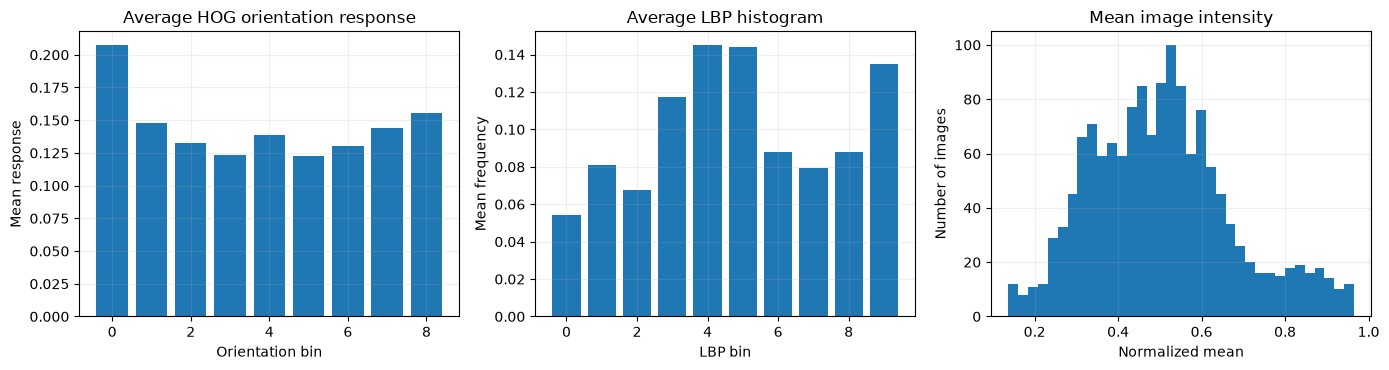

In [8]:

h_end = dims[0]
l_end = dims[0] + dims[1]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

# Plot 1: Average HOG orientation responses
# The last dimension of HOG contains 9 orientation bins.
hog_mean = X[:, :h_end].reshape(len(X), -1, 9).mean(axis=(0, 1))

ax[0].bar(np.arange(9), hog_mean)
ax[0].set_title("Average HOG orientation response")
ax[0].set_xlabel("Orientation bin")
ax[0].set_ylabel("Mean response")

# Plot 2: Average LBP texture histogram
lbp_mean = X[:, h_end:l_end].mean(axis=0)

ax[1].bar(np.arange(dims[1]), lbp_mean)
ax[1].set_title("Average LBP histogram")
ax[1].set_xlabel("LBP bin")
ax[1].set_ylabel("Mean frequency")

# Plot 3: Distribution of mean image intensity
ax[2].hist(X[:, l_end], bins=35)
ax[2].set_title("Mean image intensity")
ax[2].set_xlabel("Normalized mean")
ax[2].set_ylabel("Number of images")

for a in ax:
    a.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    OUT / "step3_feature_distributions.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()


## 5. PCA exploration


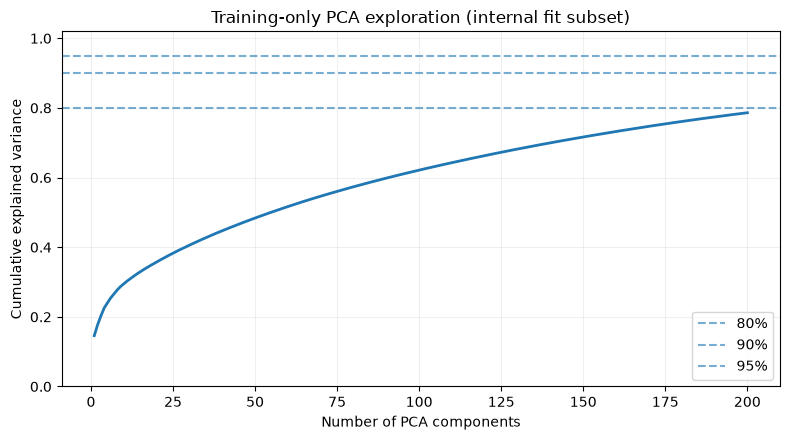

80% variance: not reached within 200 components
90% variance: not reached within 200 components
95% variance: not reached within 200 components
Internal fit/validation PCA shapes: (1151, 200) (288, 200)


In [9]:
idx_fit,idx_dev=train_test_split(np.arange(len(y)),test_size=.20,stratify=y,random_state=42)
scaler_demo=StandardScaler().fit(X[idx_fit])
X_fit_scaled=scaler_demo.transform(X[idx_fit])
X_dev_scaled=scaler_demo.transform(X[idx_dev])
# PCA uses SVD on the training-only subset; randomized solver is efficient on CPU.
n_components=min(200,len(idx_fit)-1,X.shape[1])
pca_demo=PCA(n_components=n_components,svd_solver='randomized',random_state=42).fit(X_fit_scaled)
X_fit_pca=pca_demo.transform(X_fit_scaled)
X_dev_pca=pca_demo.transform(X_dev_scaled)
cum=np.cumsum(pca_demo.explained_variance_ratio_)
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(np.arange(1,len(cum)+1),cum,linewidth=2)
for threshold in (.80,.90,.95):ax.axhline(threshold,linestyle='--',alpha=.6,label=f'{threshold:.0%}')
ax.set(xlabel='Number of PCA components',ylabel='Cumulative explained variance',title='Training-only PCA exploration (internal fit subset)')
ax.set_ylim(0,1.02);ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUT/'step3_pca_explained_variance.png',dpi=180,bbox_inches='tight');plt.show()
for threshold in (.80,.90,.95):
    if cum[-1]>=threshold: print(f'{threshold:.0%} variance: {np.searchsorted(cum,threshold)+1} components')
    else: print(f'{threshold:.0%} variance: not reached within {n_components} components')
print('Internal fit/validation PCA shapes:',X_fit_pca.shape,X_dev_pca.shape)

In [ ]:
metadata={
 'dataset':'NEU-DET','split_policy':'train only for feature extraction; validation reserved for final held-out test',
 'train_before_dedup':int(len(train)),'train_after_dedup':int(len(train_unique)),
 'heldout_test_count':int(len(heldout)),'image_size':list(SIZE),
 'hog':{'orientations':9,'pixels_per_cell':[8,8],'cells_per_block':[2,2]},
 'lbp':{'method':'uniform','P':LBP_P,'R':LBP_R},
 'feature_group_sizes':{'hog':dims[0],'lbp':dims[1],'statistics':dims[2]},
 'feature_count':int(X.shape[1]),'feature_file':feature_path.name,
 'pca_policy':'Fit scaler and PCA inside CV folds in Step 4; this notebook PCA is exploratory only',
 'class_counts':{str(k):int(v) for k,v in train_unique.label.value_counts().sort_index().items()}
}
(OUT/'step3_feature_summary.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print(json.dumps(metadata,indent=2))

{
  "dataset": "NEU-DET",
  "split_policy": "train only for feature extraction; validation reserved for final held-out test",
  "train_before_dedup": 1440,
  "train_after_dedup": 1439,
  "heldout_test_count": 360,
  "image_size": [
    64,
    64
  ],
  "hog": {
    "orientations": 9,
    "pixels_per_cell": [
      8,
      8
    ],
    "cells_per_block": [
      2,
      2
    ]
  },
  "lbp": {
    "method": "uniform",
    "P": 8,
    "R": 1
  },
  "feature_group_sizes": {
    "hog": 1764,
    "lbp": 10,
    "statistics": 12
  },
  "feature_count": 1786,
  "feature_file": "step3_train_features.npz",
  "pca_policy": "Fit scaler and PCA inside CV folds in Step 4; this notebook PCA is exploratory only",
  "class_counts": {
    "crazing": 240,
    "inclusion": 240,
    "patches": 239,
    "pitted_surface": 240,
    "rolled-in_scale": 240,
    "scratches": 240
  }
}
STEP 3 COMPLETE — ready for Step 4 model development
